# 12 — Telco: What information does the model rely on?
**Session 7 · Objective:** Read permutation importance and tree gain, then investigate
why correlated inputs can change a global ranking. This follows the first block of the
Session 7 v3 lesson; notebook 13 moves to individual predictions and the audience question.

Two customers can have the same risk and need different conversations. Before asking
why one customer scored high, ask which information the model uses across customers.
A global importance ranking answers that population question; it cannot explain an
individual score or establish what intervention would prevent churn.

In [1]:
# Locate the course CSV with paths that work across operating systems.
from pathlib import Path
# Fingerprint the source bytes so comparisons use the classroom dataset.
import hashlib
# Report the Python version alongside the numerical evidence.
import platform
# Work with arrays, logarithms and reproducible random permutations.
import numpy as np
# Keep customer fields, indices and result tables labelled.
import pandas as pd
# Build figures with explicit axes, titles and measurement units.
import matplotlib.pyplot as plt
# Report the installed scikit-learn version instead of assuming a class match.
import sklearn
# Reuse the course tree model and its built-in gain and TreeSHAP calculations.
import xgboost as xgb
# Display several readable tables from a single notebook cell.
from IPython.display import display
# Convert a complete log-odds score back to a probability with the logistic function.
from scipy.special import expit
# Route measured quantities and categories through separate preparation branches.
from sklearn.compose import ColumnTransformer
# Learn missing-value replacements from fitting customers only.
from sklearn.impute import SimpleImputer
# Measure performance loss after shuffling inputs to an already fitted model.
from sklearn.inspection import permutation_importance
# Keep the Logistic Regression algorithm selected in Session 6.
from sklearn.linear_model import LogisticRegression
# Evaluate ranking with AP and numerical probability error with Brier.
from sklearn.metrics import average_precision_score, brier_score_loss
# Recreate the stratified fitting, validation and holdout boundaries.
from sklearn.model_selection import train_test_split
# Fit preparation and prediction within a single training boundary.
from sklearn.pipeline import Pipeline
# Scale numeric inputs, encode categories and wrap the row-wise log formulas.
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

In [2]:
# Print the actual environment alongside the saved numerical evidence.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "XGBoost": xgb.__version__})
# Use readable figures and remove borders that do not help explain the result.
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
# Display four decimals in tables without rounding the underlying calculations.
pd.options.display.float_format = '{:,.4f}'.format

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'XGBoost': '3.4.1'}


## Rebuild the Session 6 experiment
Keep the selected model and ask a new question. Session 6 retained raw Logistic
Regression probabilities with two logs; neither calibration method improved validation
Brier. Its offer policy used risk at least 0.20, with uncertain incremental advantage
and an experimental pilot still needed.

We reproduce the same dataset hash, 20% stratified holdout (seed 42), and development
split into 3,943 fitting and 1,691 validation customers (seed 606). Fit only on fitting;
explain validation without refitting. The 1,409 holdout customers are not used here.
They were already inspected in Session 6 classroom evidence, so this is no fresh
untouched evaluation. Validation has also informed earlier choices: treat these
explanations as classroom diagnostics, not independent model-selection evidence.

This notebook runs independently from `notebooks/` with the root course requirements.
All population statistics stay inside the Pipeline. Numeric parsing and row-wise logs
learn nothing from other customers. `SeniorCitizen` remains categorical.

In [3]:
# Point from notebooks/ to the CSV committed with this repository.
data_path = Path('../data/telco.csv')
# Fingerprint the file before cleaning so byte-for-byte identity can be checked.
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
# This reference identifies the dataset; it is not a fitted result.
class_fingerprint = '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a'
# Stop if the dataset changed instead of silently comparing incompatible figures.
assert fingerprint == class_fingerprint, 'Dataset differs from class; investigate first.'
# Keep the verified fingerprint visible in the saved output.
print('Dataset SHA-256:', fingerprint)
# Load one row per customer.
df = pd.read_csv(data_path)
# Confirm the expected size and that customers have not been duplicated.
assert df.shape == (7043, 21) and df.customerID.is_unique
# Parse each charge independently; the eleven blank strings become missing values.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Exclude both the answer and the identifier from the model inputs.
X = df.drop(columns=['Churn', 'customerID'])
# Encode observed churn as 1 and staying as 0.
y = df['Churn'].eq('Yes').astype(int)

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [4]:
# Reserve the same 20% holdout as notebook 03 before fitting any transformation.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=42
)
# Use validation to choose corrections and cutoffs; keep fitting customers separate.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=.30, stratify=y_dev, random_state=606
)
# Check the four sample sizes from the classroom protocol.
assert (len(X_dev), len(X_test), len(X_fit), len(X_valid)) == (5634, 1409, 3943, 1691)
# Check that fitting and validation do not share customers.
assert set(X_fit.index).isdisjoint(X_valid.index)
# Check that the holdout stays outside all development decisions.
assert set(X_dev.index).isdisjoint(X_test.index)
# Check that the inner split accounts for every development customer exactly once.
assert set(X_fit.index) | set(X_valid.index) == set(X_dev.index)
# Check input/outcome order at each boundary before converting anything to arrays.
for features, labels in [(X_fit, y_fit), (X_valid, y_valid), (X_test, y_test)]:
    # Equal indices mean row i describes the same customer on both sides.
    assert features.index.equals(labels.index)
# Display actual sample sizes; these are not extrapolated campaign counts.
display(pd.Series({'Development n': len(X_dev), 'Holdout n': len(X_test),
                   'Fitting n': len(X_fit), 'Validation n': len(X_valid)}))

Development n    5634
Holdout n        1409
Fitting n        3943
Validation n     1691
dtype: int64

## Hold the algorithm fixed; change two inputs
The first model uses original inputs. The finalist retains them and adds `log1p(tenure)` and `log1p(TotalCharges)`. These row-wise logs express diminishing changes and learn no population statistics. This is **not** notebook 07's Logistic +logs versus XGBoost +polynomials comparison. `SeniorCitizen` is categorical despite its 0/1 storage.

In [5]:
# Name the measured quantities explicitly; SeniorCitizen is a category, not a measurement.
NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
# Collect all remaining original inputs as categorical columns.
CATEGORICAL = []
# Inspect each original column rather than inferring its role from its storage type.
for column in X.columns:
    # Anything outside the three measured quantities is one-hot encoded.
    if column not in NUMERIC:
        # Retain column order so the transformed model inputs stay reproducible.
        CATEGORICAL.append(column)
# Make the course's treatment of the stored 0/1 field explicit.
assert 'SeniorCitizen' in CATEGORICAL

# Define only the row-wise formula; it learns no statistics from other customers.
def add_logs(frame):
    # Copy inputs so another candidate can still use the original columns unchanged.
    result = frame.copy()
    # Compress tenure changes while allowing tenure zero: log1p(x) means log(1 + x).
    result['log_tenure'] = np.log1p(result['tenure'])
    # Missing total charges remain missing until the training imputer handles them.
    result['log_total'] = np.log1p(result['TotalCharges'])
    # Return originals plus the two added inputs.
    return result

In [6]:
# Rebuild an unfitted Pipeline each time so candidates do not share learned statistics.
def build_model(logs=False):
    # Begin with the original three measured quantities.
    numeric_columns = list(NUMERIC)
    # The baseline passes original inputs straight through.
    feature_step = 'passthrough'
    # Add logs only for the augmented candidate, retaining the original inputs.
    if logs:
        # Route the two derived numeric columns through the numeric branch too.
        numeric_columns.extend(['log_tenure', 'log_total'])
        # Adapt the simple row-wise function to the Pipeline's fit/transform interface.
        feature_step = FunctionTransformer(add_logs)
    # Learn numeric replacements and scales inside each training partition.
    numeric_preprocessing = Pipeline([
        ('impute', SimpleImputer(strategy='median')),  # Training medians replace missing values.
        ('scale', StandardScaler())  # Training means and standard deviations set the scale.
    ])
    # Keep categorical encoding separate from measured quantities.
    preprocessing = ColumnTransformer([
        ('num', numeric_preprocessing, numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)
    ])
    # Keep the regularization and optimizer identical for the two candidates.
    classifier = LogisticRegression(C=1, solver='lbfgs', max_iter=2000)
    # Fit the feature step, preprocessing and classifier within the same boundary.
    return Pipeline([('features', feature_step), ('preprocess', preprocessing),
                     ('model', classifier)])

In [7]:
# Keep Session 6's selected recipe; do not fit on customers being explained.
finalist = build_model(logs=True).fit(X_fit, y_fit)
# Keep churn probabilities aligned with validation rows; column 1 is the churn class.
probabilities = finalist.predict_proba(X_valid)[:, 1]
# Save the unshuffled AP as the common reference for importance calculations.
baseline_ap = average_precision_score(y_valid, probabilities)
# Show ranking performance before explaining what information the model uses.
print(f"Validation AP: {baseline_ap:.6f}")
# Report probability error separately so ranking and probability quality are not confused.
print(f"Validation Brier: {brier_score_loss(y_valid, probabilities):.6f}")

Validation AP: 0.675675
Validation Brier: 0.129578


## Permutation: which information would we miss most?
**Question:** How much worse does this already fitted model rank validation customers
when we break the link between one input and its customer?

First use the lesson's small housing example. The model below is fixed:
`price = 20 + 3 × area + 3 × floor`, in thousands of euros. Keep each sale price in place,
shuffle one input between homes, and predict again. There is no retraining.

In [8]:
# Create the four lesson homes; sale prices remain attached to their original rows.
homes = pd.DataFrame({'Area': [45, 70, 95, 120], 'Floor': [1, 4, 2, 5],
                      'Sale': [158, 236, 299, 380]})
# Fix one reorder so area and floor experiments use the same swap pattern.
shuffle_order = [2, 0, 3, 1]
# Collect one mean error for each version of the input data.
housing_rows = []
# Start with unchanged inputs, then disturb only area or only floor.
for field in [None, 'Area', 'Floor']:
    # Copy the original homes so a previous shuffle cannot affect the next experiment.
    changed = homes.copy()
    # Skip the swap for the original-data reference.
    if field is not None:
        # Assign reordered values positionally; keeping pandas indices would undo the shuffle.
        changed[field] = homes[field].iloc[shuffle_order].to_numpy()
    # Apply the same fixed pricing formula without learning a replacement model.
    changed['Prediction'] = 20 + 3*changed['Area'] + 3*changed['Floor']
    # Compare each altered prediction with the unchanged observed sale price.
    changed['Absolute error'] = (changed['Sale'] - changed['Prediction']).abs()
    # Name the experiment so its table and average error can be read together.
    label = 'Original' if field is None else f'Shuffle {field}'
    # Identify which input version the following table describes.
    print(label)
    # Inspect every altered value, prediction and error before averaging.
    display(changed)
    # Average absolute errors in thousands of euros, retaining the unit in the result.
    housing_rows.append({'Input': label, 'MAE (EUR thousands)': changed['Absolute error'].mean()})
# Compare the baseline and two shuffles to see which lost information hurts more.
display(pd.DataFrame(housing_rows))

Original


,Area,Floor,Sale,Prediction,Absolute error
0,45,1,158,158,0
1,70,4,236,242,6
2,95,2,299,311,12
3,120,5,380,395,15


Shuffle Area


,Area,Floor,Sale,Prediction,Absolute error
0,95,1,158,308,150
1,45,4,236,167,69
2,120,2,299,386,87
3,70,5,380,245,135


Shuffle Floor


,Area,Floor,Sale,Prediction,Absolute error
0,45,2,158,161,3
1,70,1,236,233,3
2,95,5,299,320,21
3,120,4,380,392,12


,Input,MAE (EUR thousands)
0,Original,8.2500
1,Shuffle Area,110.2500
2,Shuffle Floor,9.7500


Area shuffling increases mean absolute error much more than floor shuffling. The answer
depends on this model, evaluation data and error measure; it is not a universal ranking
of what determines house prices.

## Permutation on the Telco finalist
Now use **Average Precision (AP)**, where higher is better. Importance is
`original AP − AP after shuffling`. Shuffle each **raw** column 20 times on validation;
the Pipeline recomputes its logs. Shuffling an encoded column alone could create an
impossible category vector or leave its derived log unchanged.

In [9]:
# The scorer evaluates the complete fitted workflow on the same validation outcomes.
permutation = permutation_importance(
    finalist, X_valid, y_valid, scoring='average_precision',
    n_repeats=20, random_state=42
)
# Label mean AP losses and their shuffle variability, then rank the largest losses first.
importance = pd.DataFrame({
    'Feature': X_valid.columns,
    'AP drop': permutation.importances_mean,
    'Shuffle SD': permutation.importances_std,
}).set_index('Feature').sort_values('AP drop', ascending=False)
# Show all features, including small or negative importance estimates.
display(importance)
# Select the top-ranked raw input to translate a bar into before/after AP.
top = importance.index[0]
# Subtract the mean loss from baseline AP; this is a score change, not a probability.
print(f"Shuffle {top}: AP {baseline_ap:.3f} -> {baseline_ap - importance.loc[top, 'AP drop']:.3f}")

,AP drop,Shuffle SD
Feature,,
TotalCharges,0.2493,0.0149
InternetService,0.1036,0.0107
Contract,0.0499,0.0084
StreamingMovies,0.0230,0.0056
MultipleLines,0.0195,0.0055
StreamingTV,0.0195,0.0053
tenure,0.0175,0.0055
PaperlessBilling,0.0097,0.0045
TechSupport,0.0074,0.0037


Shuffle TotalCharges: AP 0.676 -> 0.426


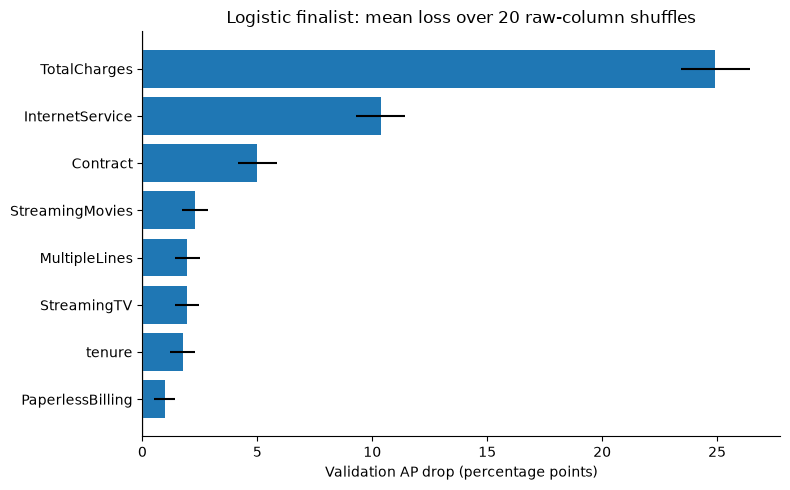

In [10]:
# Multiply by 100 only for display: an AP drop of .10 is 10 percentage points.
shown = importance.head(8).iloc[::-1]
# Allocate enough height for eight readable feature names.
fig, ax = plt.subplots(figsize=(8, 5))
# Draw mean losses with shuffle standard deviations, not confidence intervals.
ax.barh(shown.index, 100*shown['AP drop'], xerr=100*shown['Shuffle SD'])
# Mark no performance change so positive and negative losses have a clear reference.
ax.axvline(0, color='grey', linewidth=1)
# State the evaluation population, repetition count and units in the plot.
ax.set(xlabel='Validation AP drop (percentage points)',
       title='Logistic finalist: mean loss over 20 raw-column shuffles')
# Keep long feature names and axis labels within the saved figure.
plt.tight_layout()
# Render the completed importance chart in this notebook's output.
plt.show()

Read the first bar together with the printed AP before and after the shuffle. A positive
drop means the model relied on that information for ranking these customers. Near zero
can mean little use, redundant information or insufficient evaluation evidence. A negative
drop means the shuffled version scored better in this experiment; it does not prove that
removing and retraining without the feature will help.

The error bars show variability **across shuffles of these fixed customers**. They are
not confidence intervals over new samples, refitting or model selection. Permutation
does not show whether a higher feature value raises or lowers an individual's risk.

## Tree gain: which questions helped the trees learn?
**Question:** Which features' splits contributed most to improvement of the **training
objective**? In the lesson's teaching split, 20 customers contain 10 leavers and 10 stayers.
Predicting a single class misses 10. A contract split gives groups (8 leave, 2 stay) and
(2 leave, 8 stay), missing 4 in total. This illustrates credit for improvement; XGBoost's
actual gain uses its regularized objective, not this count of classification mistakes.

In [11]:
# The lesson's miniature gain accounting, separate from fitted-model evidence.
split_gains = pd.DataFrame({'Feature': ['Contract', 'tenure', 'Contract'],
                            'Illustrative gain': [6, 4, 2]})
# Add credit across repeated uses of the same feature: Contract receives 6 + 2.
gain_totals = split_gains.groupby('Feature')['Illustrative gain'].sum()
# Divide by all 12 gain units to distinguish total credit from its proportional share.
display(pd.DataFrame({'Total': gain_totals, 'Share': gain_totals / gain_totals.sum()}))

,Total,Share
Feature,,
Contract,8,0.6667
tenure,4,0.3333


In [12]:
# Session 4's raw-input XGBoost recipe is a comparison, not a new selection.
tree = build_model(logs=False)
# Replace only the classifier, keeping the raw-input preprocessing and classroom settings.
tree.set_params(model=xgb.XGBClassifier(
    n_estimators=100, learning_rate=.1, max_depth=2,
    tree_method='hist', eval_metric='logloss', random_state=42, n_jobs=1
))
# Learn tree splits and preparation from fitting rows, never validation customers.
tree.fit(X_fit, y_fit)
# Score the same validation customers as the Logistic finalist without refitting.
tree_probabilities = tree.predict_proba(X_valid)[:, 1]
# Measure validation ranking before interpreting the tree explanation.
tree_ap = average_precision_score(y_valid, tree_probabilities)
# Expose the computed tree score for comparison with the class evidence.
print(f"XGBoost validation AP: {tree_ap:.6f}")

XGBoost validation AP: 0.678846


In [13]:
# Track each encoded column back to the raw field that generated it.
def encoded_groups(pipeline):
    # Inspect the fitted transformer so the mapping follows its actual output order.
    preprocessing = pipeline.named_steps['preprocess']
    # Read numeric field names from the first branch; these appear first in the encoded matrix.
    numeric = preprocessing.transformers_[0][2]
    # Read the raw categorical names in the second branch's fitted order.
    categorical = preprocessing.transformers_[1][2]
    # Recover learned category levels to count each field's one-hot columns.
    encoder = preprocessing.named_transformers_['cat']
    # Build one raw-feature label for every column received by the classifier.
    labels = []
    # Map numeric outputs in order, including any added logarithms.
    for name in numeric:
        # Treat tenure and its deterministic log as one source of information.
        if name == 'log_tenure':
            # Assign the log term to the original tenure field for grouped explanations.
            name = 'tenure'
        # Apply the same grouping rule to the log of accumulated charges.
        elif name == 'log_total':
            # Assign the derived term to the raw billing field that generated it.
            name = 'TotalCharges'
        # Append the source label in exactly the same position as its transformed column.
        labels.append(name)
    # Pair each categorical input with the levels learned for that input.
    for name, levels in zip(categorical, encoder.categories_):
        # The default encoder emits one column for each learned level.
        for level in levels:
            # Append the source label in exactly the same position as its transformed column.
            labels.append(name)
    # Return an array so a Boolean mask can select all columns belonging to one raw field.
    return np.array(labels)

In [14]:
# total_gain adds improvements across all splits using an encoded column.
booster = tree.named_steps['model'].get_booster()
# Request summed objective improvements; average gain per split would answer a different question.
encoded_gain = booster.get_score(importance_type='total_gain')
# Map one-hot positions back to their original customer fields.
tree_groups = encoded_groups(tree)
# Collect a total for every raw field, including those never used by a split.
gain_rows = []
# Aggregate all encoded columns that came from the same raw input.
for name in X.columns:
    # Reset the accumulated gain before processing another field.
    total = 0.0
    # Find the encoded positions associated with this raw field.
    for position in np.flatnonzero(tree_groups == name):
        # Add each column's gain; unused columns are absent from XGBoost's dictionary and count as zero.
        total += encoded_gain.get(f'f{position}', 0.0)
    # Store the raw-field total rather than ranking its one-hot categories separately.
    gain_rows.append({'Feature': name, 'Total gain': total})
# Use field names as row labels for the side-by-side comparison.
gain = pd.DataFrame(gain_rows).set_index('Feature')
# Normalize summed gains into shares of the training objective improvement.
gain['Training gain share'] = gain['Total gain'] / gain['Total gain'].sum()

# Hold the fitted XGBoost model fixed when comparing the two explanations.
tree_permutation = permutation_importance(
    tree, X_valid, y_valid, scoring='average_precision',
    n_repeats=20, random_state=42
)
# Attach held-out AP losses in the original feature order used to build this table.
gain['Validation AP drop'] = tree_permutation.importances_mean
# Inspect training credit beside validation reliance before comparing their ranks.
display(gain.sort_values('Training gain share', ascending=False))

,Total gain,Training gain share,Validation AP drop
Feature,,,
Contract,"3,116.0580",0.4165,0.0673
tenure,"1,297.0511",0.1734,0.1229
InternetService,806.7618,0.1078,0.0425
OnlineSecurity,532.2462,0.0711,0.0076
TechSupport,470.5395,0.0629,0.0104
PaymentMethod,370.2132,0.0495,0.0047
MonthlyCharges,349.5006,0.0467,0.0243
TotalCharges,206.1372,0.0276,0.0028
PaperlessBilling,118.0049,0.0158,0.0078


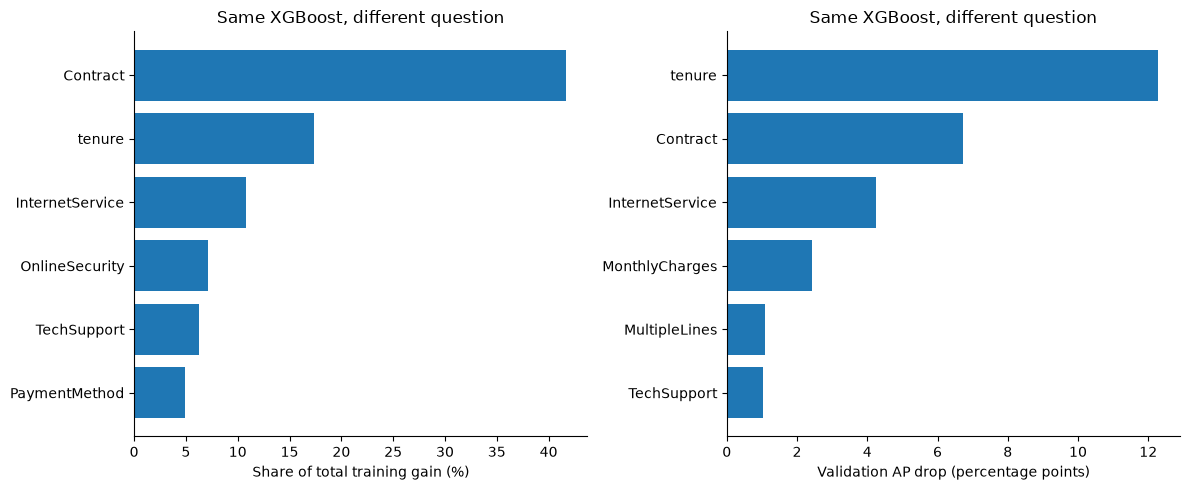

,Training gain share,Validation AP drop
Feature,,
tenure,2.0000,1.0000
Contract,1.0000,2.0000
InternetService,3.0000,3.0000


In [15]:
# Place training gain and validation permutation side by side for the same XGBoost.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Reuse the plotting steps while keeping each measure's meaning and units explicit.
for ax, column, label in [
    (axes[0], 'Training gain share', 'Share of total training gain (%)'),
    (axes[1], 'Validation AP drop', 'Validation AP drop (percentage points)')
]:
    # Select each measure's own top six and reverse them so the largest bar appears at the top.
    shown = gain.sort_values(column, ascending=False).head(6).iloc[::-1]
    # Express gain shares as percentages and AP losses as percentage points.
    ax.barh(shown.index, 100*shown[column])
    # Keep the two different units visible instead of implying that bar lengths are comparable.
    ax.set_xlabel(label)
    # Remind the reader that the explanation method changes while the fitted model stays fixed.
    ax.set_title('Same XGBoost, different question')
# Separate the panels so long labels do not overlap.
plt.tight_layout()
# Display the two completed rankings together.
plt.show()

# Convert values into descending ranks; equal values share the lowest rank in their tie.
ranks = gain[['Training gain share', 'Validation AP drop']].rank(ascending=False, method='min')
# Read the three classroom signals directly to locate disagreements between methods.
display(ranks.loc[['tenure', 'Contract', 'InternetService']])

Both rankings can be right. Training gain describes how the trees were built;
validation permutation describes dependence of their measured ranking performance
on a raw input. Gain can favor variables with many potential split points, and correlated
features can receive unequal credit depending on which the trees used first. It does
not estimate held-out performance or a customer's reason for receiving an offer.
Compare gain and permutation on the **same XGBoost**, not gain on one model against
permutation on a different one. Gain percentages are shares of an objective improvement;
an AP drop is a change in a ranking metric. The units are different.

## Correlation: what does each billing detail add?
**Question:** How does the answer change when a related input stays available?
Tenure and total charges tend to rise together. First measure that relationship, then
compare three deliberately different perturbations on the Logistic finalist.

In [16]:
# Identify the evaluation population used for this descriptive relationship.
print('Validation correlation:')
# Measure the linear association that can make separate feature perturbations hard to interpret.
display(X_valid[['tenure', 'TotalCharges']].corr())
# Inspect an actual supported pairing before inventing altered customers.
display(X_valid.loc[X_valid['tenure'] > 48, NUMERIC].sort_values('TotalCharges').tail(3))

Validation correlation:


,tenure,TotalCharges
tenure,1.0000,0.8338
TotalCharges,0.8338,1.0000


,tenure,MonthlyCharges,TotalCharges
6768,72,117.5000,"8,670.1000"
4586,72,118.7500,"8,672.4500"
4610,72,117.8000,"8,684.8000"


**One at a time:** the original permutation leaves the related input unchanged.
It can hide reliance through redundancy, and it can create unusual tenure/charge pairs.
**Within similar groups:** shuffle one field only inside deciles of the other.
This approximately asks about extra information among roughly comparable customers.
It is coarse conditioning on one field, not a fully conditional importance estimator.
**Together:** move tenure and total charges as a pair. Their internal pairing survives,
although relationships with other fields can still break.

In [17]:
# Match the classroom random sequence: its SHAP dot sample consumes the first draw.
rng = np.random.default_rng(7)
# Consume the same display-sample draw as the class script before generating joint shuffles.
_ = rng.choice(len(X_valid), size=260, replace=False)
# Name the two fields whose internal pairing we want to preserve.
paired_fields = ['tenure', 'TotalCharges']
# Keep each repeated joint AP loss so it can be averaged after all shuffles.
joint_losses = []
# Repeat the perturbation to reduce dependence on a single random ordering.
for repeat in range(20):
    # Start from intact validation rows for every joint perturbation.
    changed = X_valid.copy()
    # Generate one row order that will be applied to both fields together.
    order = rng.permutation(len(X_valid))
    # Move each tenure/charge pair positionally without changing outcomes or other inputs.
    changed[paired_fields] = X_valid[paired_fields].iloc[order].to_numpy()
    # Recompute derived logs through the fitted Pipeline and measure AP against unchanged outcomes.
    shuffled_ap = average_precision_score(y_valid, finalist.predict_proba(changed)[:, 1])
    # Record the loss relative to the same unperturbed Logistic finalist.
    joint_losses.append(baseline_ap - shuffled_ap)

# Store one within-decile importance estimate for each direction of the comparison.
conditional_losses = {}
# Alternate the shuffled field and the related field used to define comparable customers.
for field, conditioning in [('tenure', 'TotalCharges'), ('TotalCharges', 'tenure')]:
    # Approximate conditioning with quantile groups; repeated edges may yield fewer than ten groups.
    bins = pd.qcut(X_valid[conditioning], 10, duplicates='drop')
    # Collect row positions within populated bins; missing conditioning values are not assigned a bin.
    positions_by_bin = bins.groupby(bins, observed=True).indices.values()
    # Preserve the original field values and positional order before any within-bin shuffle.
    original = X_valid[field].to_numpy()
    # Reset repeated losses for the current shuffled field.
    losses = []
    # Repeat the perturbation to reduce dependence on a single random ordering.
    for repeat in range(20):
        # Begin each repeat with original values, leaving rows outside populated bins unchanged.
        shuffled = original.copy()
        # Only exchange values among customers in the same conditioning group.
        for positions in positions_by_bin:
            # Break the field/customer link locally while retaining approximate similarity in the other field.
            shuffled[positions] = rng.permutation(original[positions])
        # Replace only the chosen raw field so the Pipeline can recompute its derived features.
        changed = X_valid.assign(**{field: shuffled})
        # Recompute derived logs through the fitted Pipeline and measure AP against unchanged outcomes.
        shuffled_ap = average_precision_score(y_valid, finalist.predict_proba(changed)[:, 1])
        # Record this local-shuffle AP loss on the unchanged validation outcomes.
        losses.append(baseline_ap - shuffled_ap)
    # Average the twenty within-decile losses for this field.
    conditional_losses[field] = np.mean(losses)

# Align standalone and approximate conditional losses by field name.
comparison = pd.DataFrame({
    'One at a time': importance.loc[paired_fields, 'AP drop'],
    'Within deciles of the other': pd.Series(conditional_losses),
})
# Compare what each field adds under the two different perturbation schemes.
display(comparison)
# Report joint reliance separately; it is not the sum of the standalone losses.
print(f"Move both together: mean AP drop {np.mean(joint_losses):.6f}")

,One at a time,Within deciles of the other
tenure,0.0175,0.0010
TotalCharges,0.2493,0.0345


Move both together: mean AP drop 0.195985


The within-decile tenure loss is much smaller than the standalone loss: ask what it
adds once total charges are approximately retained. The joint loss is not the sum of
standalone losses. None of these experiments establishes that changing a bill or
tenure would cause a customer to leave. These are dependencies of a fitted predictor
under particular input changes, not causal intervention effects.

### Read the classroom evidence
The v3 reference has validation AP about **0.675675** for the finalist and **0.678846**
for XGBoost. XGBoost ranks tenure first by validation permutation but contract first by
total training gain. The tenure/total-charge correlation is about **0.834**. The joint
AP drop is about **0.196**, while within-decile drops are about **0.001** for tenure
and **0.034** for total charges. Compare these with the actual calculated outputs above;
we do not replace results with class constants. Different versions can change small values.

**Observation:** Global importance changes with the question and correlated inputs.
**Decision:** Check the data and explanation assumptions before defending reliance on
a variable. **Question:** Could the most important global feature push one customer's
score down? Continue with notebook 13 to find out.

Sources: local Session 7 v3 HTML, its embedded experiment/evidence, and Session 6
notebooks 09–11. The instructor files are read-only references; executing this notebook
needs only this repository. Technical background: [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html),
[correlated inputs](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html)
and [XGBoost gain](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.get_score).